<a href="https://colab.research.google.com/github/Doyinakinloye/Recommendation-System-Project/blob/main/Recommendation_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Exploratory Data Analysis

In [ ]:
df = pd.read_csv(
    "/content/drive/MyDrive/Amazon recommendation system/Amazon_Reviews.csv",
    engine="python",
    on_bad_lines="skip"
)

In [ ]:
df.head()

,Reviewer Name,Profile Link,Country,Review Count,Review Date,Rating,Review Title,Review Text,Date of Experience
0,Eugene ath,/users/66e8185ff1598352d6b3701a,US,1 review,2024-09-16T13:44:26.000Z,Rated 1 out of 5 stars,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ...","September 16, 2024"
1,Daniel ohalloran,/users/5d75e460200c1f6a6373648c,GB,9 reviews,2024-09-16T18:26:46.000Z,Rated 1 out of 5 stars,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...,"September 16, 2024"
2,p fisher,/users/546cfcf1000064000197b88f,GB,90 reviews,2024-09-16T21:47:39.000Z,Rated 1 out of 5 stars,I informed these reprobates,I informed these reprobates that I WOULD NOT B...,"September 16, 2024"
3,Greg Dunn,/users/62c35cdbacc0ea0012ccaffa,AU,5 reviews,2024-09-17T07:15:49.000Z,Rated 1 out of 5 stars,Advertise one price then increase it on website,I have bought from Amazon before and no proble...,"September 17, 2024"
4,Sheila Hannah,/users/5ddbe429478d88251550610e,GB,8 reviews,2024-09-16T18:37:17.000Z,Rated 1 out of 5 stars,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...,"September 16, 2024"


In [ ]:
df.columns

Index(['Reviewer Name', 'Profile Link', 'Country', 'Review Count',
       'Review Date', 'Rating', 'Review Title', 'Review Text',
       'Date of Experience'],
      dtype='object')

In [ ]:
df_clean = df.copy()

In [ ]:
len(df)

21214

In [ ]:
# 1. Dataset structure and information
print("=== Dataset Info ===")
df_clean.info()

# 2. Check for missing values
print("\n=== Missing Values ===")
print(df_clean.isnull().sum())

# 3. Clean 'Rating' column to get numeric values
if 'Rating' in df_clean.columns:
    df_clean['Rating_numeric'] = df_clean['Rating'].str.extract(r'Rated (\d) out of 5 stars').astype(float)
    print("\n=== Cleaned Rating Distribution ===")
    print(df_clean['Rating_numeric'].value_counts(dropna=False))

# 4. Clean 'Review Count' column to get numeric values
if 'Review Count' in df_clean.columns:
    df_clean['Review_Count_numeric'] = df_clean['Review Count'].str.extract(r'(\d+)').astype(float)

# 5. Display descriptive statistics for numeric fields
print("\n=== Descriptive Statistics ===")
print(df_clean[['Rating_numeric', 'Review_Count_numeric']].describe())

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21214 entries, 0 to 21213
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Reviewer Name       21214 non-null  object
 1   Profile Link        21163 non-null  object
 2   Country             21054 non-null  object
 3   Review Count        21055 non-null  object
 4   Review Date         21055 non-null  object
 5   Rating              21055 non-null  object
 6   Review Title        21055 non-null  object
 7   Review Text         21055 non-null  object
 8   Date of Experience  20947 non-null  object
dtypes: object(9)
memory usage: 1.5+ MB

=== Missing Values ===
Reviewer Name           0
Profile Link           51
Country               160
Review Count          159
Review Date           159
Rating                159
Review Title          159
Review Text           159
Date of Experience    267
dtype: int64

=== Cleaned Rating Distribution

In [ ]:
df.columns

Index(['Reviewer Name', 'Profile Link', 'Country', 'Review Count',
       'Review Date', 'Rating', 'Review Title', 'Review Text',
       'Date of Experience'],
      dtype='object')

In [ ]:
# Drop the 'Profile Link', 'Review count', 'Rating'
df_clean = df_clean.drop(columns=["Profile Link", "Review Count", "Rating"])

In [ ]:
df_clean.columns

Index(['Reviewer Name', 'Country', 'Review Date', 'Review Title',
       'Review Text', 'Date of Experience', 'Rating_numeric',
       'Review_Count_numeric'],
      dtype='object')

In [ ]:
# convert date of experience column to datetime
df_clean['Date of Experience'] = pd.to_datetime(df_clean['Date of Experience'], errors='coerce')
df_clean['Date of Experience']

,Date of Experience
0,2024-09-16
1,2024-09-16
2,2024-09-16
3,2024-09-17
4,2024-09-16
...,...
21209,2009-03-22
21210,2008-12-31
21211,2008-09-16
21212,2008-04-28


In [ ]:
df_clean['Review Date'] = pd.to_datetime(df_clean['Review Date']).dt.date
df_clean['Review Date']

,Review Date
0,2024-09-16
1,2024-09-16
2,2024-09-16
3,2024-09-17
4,2024-09-16
...,...
21209,2009-03-22
21210,2008-12-31
21211,2008-09-16
21212,2008-04-28


In [ ]:
# Check if the two columsn are identical
df_clean['Review Date'].equals(df_clean['Date of Experience'])

False

In [ ]:
df_clean.head()

,Reviewer Name,Country,Review Date,Review Title,Review Text,Date of Experience,Rating_numeric,Review_Count_numeric
0,Eugene ath,US,2024-09-16,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ...",2024-09-16,1.0,1.0
1,Daniel ohalloran,GB,2024-09-16,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...,2024-09-16,1.0,9.0
2,p fisher,GB,2024-09-16,I informed these reprobates,I informed these reprobates that I WOULD NOT B...,2024-09-16,1.0,90.0
3,Greg Dunn,AU,2024-09-17,Advertise one price then increase it on website,I have bought from Amazon before and no proble...,2024-09-17,1.0,5.0
4,Sheila Hannah,GB,2024-09-16,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...,2024-09-16,1.0,8.0


In [ ]:
df_clean['Reviewer Name'].nunique()

18531

In [ ]:
# Drop rows where Rating_numeric is NaN
df_clean = df_clean.dropna(subset=['Rating_numeric'])
print("New shape of df_clean:", df_clean.shape)
print("Remaining missing ratings:", df_clean['Rating_numeric'].isna().sum())

New shape of df_clean: (21055, 8)
Remaining missing ratings: 0


In [ ]:
df_clean.isna().sum()

,0
Reviewer Name,0
Country,1
Review Date,0
Review Title,0
Review Text,0
Date of Experience,108
Rating_numeric,0
Review_Count_numeric,0


In [ ]:
df_clean[df_clean['Date of Experience'].isna()]

,Reviewer Name,Country,Review Date,Review Title,Review Text,Date of Experience,Rating_numeric,Review_Count_numeric
18967,Michelle Bergeson,US,2016-05-04,Love AMAZON!!,I turn to Amazon for all my gift giving and ha...,NaT,5.0,2.0
18969,Lemon Crisp,SG,2016-05-03,Perfect Place for shopping,I love shopping in Amazon.,NaT,5.0,4.0
19006,Creamy Jam,SG,2016-03-16,Purchase Experience,I love buying the products from Amazon.,NaT,5.0,3.0
19025,DeeJay84,TR,2016-02-19,Sometimes Problems.,Sometimes there are a few problems with Amazon.,NaT,3.0,1.0
19032,hydrogen,PT,2016-02-17,You could find everything,It's a good site to buy products.,NaT,4.0,3.0
...,...,...,...,...,...,...,...,...
21075,Ken Richards,GB,2011-09-19,Very good company to deal with,Overall I rate Amazon as A-. Deliveries are s...,NaT,4.0,2.0
21137,Elizabeth Sylvester-Gray,GB,2011-08-10,Electronic items and CDs/DVDs,Service is excellent and all merchandise lives...,NaT,5.0,9.0
21143,Rob,GB,2011-08-03,The best,Amazon is the only place I will go to on line ...,NaT,5.0,4.0
21146,ash amliwala,GB,2011-08-03,superb site for all my needs,Great site for buying on-line and free postage...,NaT,5.0,58.0


In [ ]:
# Fill missing 'Date of Experience' values with 'Review Date'
df_clean['Date of Experience'] = df_clean['Date of Experience'].fillna(pd.to_datetime(df_clean['Review Date']))

In [ ]:
df_clean['Country'] = df_clean['Country'].fillna(df_clean['Country'].mode)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21055 entries, 0 to 21213
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Reviewer Name         21055 non-null  object        
 1   Country               21055 non-null  object        
 2   Review Date           21055 non-null  object        
 3   Review Title          21055 non-null  object        
 4   Review Text           21055 non-null  object        
 5   Date of Experience    21055 non-null  datetime64[ns]
 6   Rating_numeric        21055 non-null  float64       
 7   Review_Count_numeric  21055 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(5)
memory usage: 1.4+ MB


In [ ]:
df_clean.isna().sum()

,0
Reviewer Name,0
Country,0
Review Date,0
Review Title,0
Review Text,0
Date of Experience,0
Rating_numeric,0
Review_Count_numeric,0


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21055 entries, 0 to 21213
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Reviewer Name         21055 non-null  object        
 1   Country               21055 non-null  object        
 2   Review Date           21055 non-null  object        
 3   Review Title          21055 non-null  object        
 4   Review Text           21055 non-null  object        
 5   Date of Experience    21055 non-null  datetime64[ns]
 6   Rating_numeric        21055 non-null  float64       
 7   Review_Count_numeric  21055 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(5)
memory usage: 1.4+ MB


In [ ]:
df_clean.describe()

,Date of Experience,Rating_numeric,Review_Count_numeric
count,21055,21055.000000,21055.000000
mean,2020-11-16 20:48:42.403229696,2.186654,8.488720
min,2007-08-27 00:00:00,1.000000,1.000000
25%,2019-09-14 00:00:00,1.000000,1.000000
50%,2021-07-23 00:00:00,1.000000,3.000000
75%,2023-05-11 00:00:00,4.000000,8.000000
max,2024-09-17 00:00:00,5.000000,633.000000
std,NaN,1.676769,18.239247


In [ ]:
df_clean.describe(include='object')

,Reviewer Name,Country,Review Date,Review Title,Review Text
count,21055,21055,21055,21055,21055
unique,18375,149,3655,19277,20407
top,customer,US,2021-01-11,Excellent,Review text not found
freq,72,9286,33,52,630


In [ ]:
(df_clean['Review Title'].value_counts())[:15]

,count
Review Title,
Excellent,52
Amazon,43
I love Amazon,38
Terrible customer service,35
Horrible customer service,35
Great service,29
Terrible,25
Good,25
Good service,23


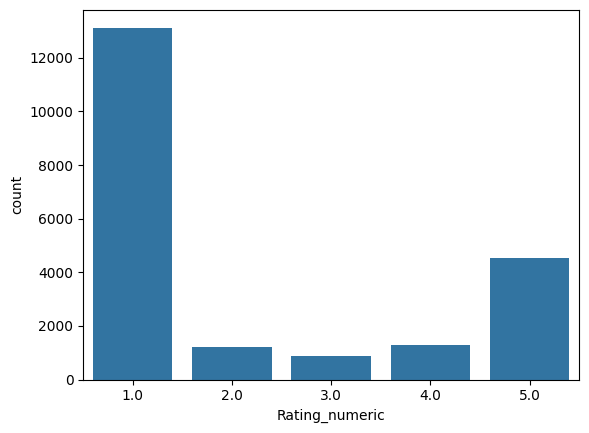

In [ ]:
import seaborn as sns

sns.countplot(x='Rating_numeric', data=df_clean)
plt.show()

Majority of the reviews were 1 stars

#### Split the data into train and validation sets

In [ ]:
len(df_clean)

21055

In [ ]:
# combine the 'review text' and 'review title' for better embedding context
df_clean["content"] = df_clean["Review Title"] + " " + df_clean["Review Text"]
df_clean[["content", "Review Title", "Review Text"]].head()

,content,Review Title,Review Text
0,A Store That Doesn't Want to Sell Anything I r...,A Store That Doesn't Want to Sell Anything,"I registered on the website, tried to order a ..."
1,Had multiple orders one turned up and… Had mul...,Had multiple orders one turned up and…,Had multiple orders one turned up and driver h...
2,I informed these reprobates I informed these r...,I informed these reprobates,I informed these reprobates that I WOULD NOT B...
3,Advertise one price then increase it on websit...,Advertise one price then increase it on website,I have bought from Amazon before and no proble...
4,If I could give a lower rate I would If I coul...,If I could give a lower rate I would,If I could give a lower rate I would! I cancel...


In [ ]:
# vectorize the content column
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english", max_features=1000)
tfidf_matrix = vectorizer.fit_transform(df_clean["content"])

In [ ]:
# Visualize the tfidf matrix
vectorizer.vocabulary_

In [ ]:
# compute the cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

cosine_sim = cosine_similarity(tfidf_matrix)

In [ ]:
cosine_sim.shape

(21055, 21055)

In [ ]:
# test the similarity on a single review
similar_scores = list(enumerate(cosine_sim[0]))

similar_scores[:5], len(similar_scores)

([(0, np.float64(1.0000000000000002)),
  (1, np.float64(0.02025895877320248)),
  (2, np.float64(0.08368495443592758)),
  (3, np.float64(0.11287336934932185)),
  (4, np.float64(0.032849122387143374))],
 21055)

In [ ]:
# sort by similarity
similar_scores = sorted(similar_scores, key=lambda x: x[1], reverse=True)

In [ ]:
similar_scores[1:6]

[(19937, np.float64(0.3053695826851256)),
 (15655, np.float64(0.29826298500553217)),
 (8715, np.float64(0.28704154891598255)),
 (18437, np.float64(0.28704154891598255)),
 (20704, np.float64(0.27009353515806894))]

In [ ]:
top_indices = [i[0] for i in similar_scores[1:6]]

df_clean.iloc[top_indices][
    ["Review Title", "Rating_numeric"]
]

,Review Title,Rating_numeric
20010,gd store,3.0
15655,Tried to buy a gift card,1.0
8715,Great store!!,5.0
18437,great store liked the games section,5.0
20842,Brilliant store,5.0


#### Content-Based Recommendation Function

In [ ]:
def recommend(review_index, n=5):
  # stores the a column of the cosine similarity matrix in a variable
  sim_scores = list(enumerate(cosine_sim[review_index]))
  # sorts out the similarity scores that specific index
  sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
  # get the top n indices
  top_indices = [i[0] for i in sim_scores[1:n+1]]

  return df_clean.iloc[top_indices][["Review Title", "Rating_numeric"]]

In [ ]:
recommend(5)

,Review Title,Rating_numeric
5744,Could not help,2.0
760,Most terrible customer service.,1.0
2111,Terrible customer service,1.0
8162,Can not get any help with customer…,1.0
10960,Terrible service terrible customer…,1.0


In [ ]:
df_clean['content'][5]

'Terrible, I had to hang up and call back  Terrible you get customer service reps that are clearly home, you hear children and family scenarios in the background. These people lie when asked if they have a quiet environment to work in and I get minimal help if they speak English well enough.'

In [ ]:
df_clean.columns

Index(['Reviewer Name', 'Country', 'Review Date', 'Review Title',
       'Review Text', 'Date of Experience', 'Rating_numeric',
       'Review_Count_numeric', 'content'],
      dtype='object')